# Módulo 10: Visualización de datos, parte 2

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [m10-visualizacion-2-solucion.ipynb](m10-visualizacion-2-solucion.ipynb). No es una tarea entregada del programa.

Los datos públicos rara vez llegan listos para graficar: traen encabezados de varias filas, codificaciones antiguas, números escritos como texto y regiones mezcladas con países. En esta lección limpiamos un archivo de indicadores demográficos de la ONU (`crecimiento-poblacional.csv`), lo reorganizamos y medimos qué variables se mueven juntas con la **correlación de Pearson**, para terminar con gráficos de seaborn pensados para comunicar.

1. Datos largos y anchos
2. Encabezados desordenados y codificación
3. Convertir texto a número
4. Filtrar y combinar con `merge`
5. De largo a ancho con `pivot`
6. Valores faltantes: descartar o imputar
7. Correlación de Pearson
8. Gráficos con seaborn
9. Diseño para impacto visual
10. Errores frecuentes
11. Ejercicio

## 1. Datos largos y anchos

La misma información puede guardarse de dos formas:

| Formato | Estructura | Para qué sirve |
| --- | --- | --- |
| **Largo** | Una fila por observación: entidad, variable, valor | Almacenar y filtrar; así se publican muchas bases de datos |
| **Ancho** | Una fila por entidad y una columna por variable | Comparar variables, calcular correlaciones y graficar una contra otra |

Para relacionar dos indicadores hay que tenerlos en columnas distintas, es decir, en formato ancho.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

largo = pd.DataFrame({
    "pais": ["A", "A", "B", "B", "C", "C"],
    "indicador": ["ingreso", "escolaridad"] * 3,
    "valor": [30, 9, 45, 12, 25, 8],
})
print(largo, end="\n\n")

ancho_ejemplo = largo.pivot(index="pais", columns="indicador", values="valor")
print(ancho_ejemplo)

  pais    indicador  valor
0    A      ingreso     30
1    A  escolaridad      9
2    B      ingreso     45
3    B  escolaridad     12
4    C      ingreso     25
5    C  escolaridad      8

indicador  escolaridad  ingreso
pais                           
A                    9       30
B                   12       45
C                    8       25


## 2. Encabezados desordenados y codificación

Antes de usar `read_csv` conviene mirar las primeras líneas del archivo tal cual. Así se descubren dos problemas habituales: una fila de título encima de los nombres de las columnas y una **codificación** distinta de UTF-8. La codificación es la tabla que traduce bytes a caracteres; si se elige mal, los acentos fallan o la lectura se detiene con un `UnicodeDecodeError`.

En este archivo, la primera línea es un título y la segunda contiene los nombres reales, así que se lee con `header=1`. La codificación es **Windows-1252** (`cp1252`), una variante de ISO-8859-1 (`latin-1`): ambas leen bien los acentos, pero solo `cp1252` interpreta el apóstrofo tipográfico de "Côte d’Ivoire".

In [2]:
archivo = "crecimiento-poblacional.csv"

with open(archivo, encoding="cp1252") as f:
    for _ in range(3):
        print(f.readline().strip()[:110])

try:
    pd.read_csv(archivo)    # por defecto, UTF-8
except UnicodeDecodeError as e:
    print("\nUnicodeDecodeError:", str(e)[:80], end="\n\n")

for codificacion in ["latin-1", "cp1252"]:
    prueba = pd.read_csv(archivo, encoding=codificacion, header=1)
    nombre = prueba.loc[prueba["Unnamed: 1"].str.startswith("C\xf4te"), "Unnamed: 1"].iloc[0]
    print(f"{codificacion:8} {nombre!r}")

T03,Population growth and indicators of fertility and mortality,,,,,
Region/Country/Area,,Year,Series,Value,Footnotes,Source
1,"Total, all countries or areas",2010,Population annual rate of increase (percent),1.3,,"United Nations Popul

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xf4 in position 182487: invalid continuation by

latin-1  'Côte d\x92Ivoire'
cp1252   'Côte d’Ivoire'


## 3. Convertir texto a número

Si una sola celda de una columna no es un número válido, pandas guarda la columna entera como texto (`object`). `pd.to_numeric(serie, errors="coerce")` convierte lo que puede y sustituye por `NaN` lo que no. Es cómodo, pero peligroso: hay que revisar **qué** se convirtió en `NaN`, porque a veces son datos válidos escritos de otra forma.

In [3]:
crudo = pd.read_csv(archivo, encoding="cp1252", header=1)
print("Tipo de Value:", crudo["Value"].dtype)

convertido = pd.to_numeric(crudo["Value"], errors="coerce")
perdidos = crudo.loc[convertido.isna(), "Value"]
print(f"Valores que pasaron a NaN: {len(perdidos)}")
print(perdidos.unique())

Tipo de Value: object
Valores que pasaron a NaN: 11
['1,052' '1,303' '1,125' '1,063' '1,040' '1,123' '1,113' '1,047' '1,060'
 '1,225' '1,223']


Los valores perdidos eran cifras con separador de miles, como `1,052`. No faltaban: estaban escritos con coma. El parámetro `thousands=","` de `read_csv` los lee correctamente. Después renombramos las columnas a nombres cortos en español.

In [4]:
datos = pd.read_csv(archivo, encoding="cp1252", header=1, thousands=",")
datos = datos.rename(columns={"Region/Country/Area": "codigo", "Unnamed: 1": "area",
                              "Year": "anio", "Series": "serie", "Value": "valor"})
datos = datos[["codigo", "area", "anio", "serie", "valor"]]

print(datos.dtypes)
print("NaN en valor:", datos["valor"].isna().sum())
print("Años:", sorted(datos["anio"].unique().tolist()))

codigo      int64
area       object
anio        int64
serie      object
valor     float64
dtype: object
NaN en valor: 0
Años: [2010, 2015, 2020, 2022]


## 4. Filtrar y combinar con `merge`

El archivo mezcla el total mundial y regiones (África, Américas…) con países y territorios. Si se dejan juntos, cada región cuenta como un "país" más y repite información. Aquí los agregados aparecen al principio y al final del listado, así que nos quedamos con las áreas entre "Afghanistan" y "Zimbabwe".

Después, `pd.merge` une dos tablas por una columna clave, como un `JOIN` de SQL. Con `how="inner"` (el valor por defecto) solo se conservan las claves presentes en ambas. Para relacionar dos indicadores de 2015 filtramos cada serie y las unimos por `area`.

In [5]:
areas = datos["area"].drop_duplicates().tolist()
inicio, fin = areas.index("Afghanistan"), areas.index("Zimbabwe")
print("Agregados excluidos:", areas[:inicio][:4], "...", areas[fin + 1:])

paises = datos[datos["area"].isin(areas[inicio:fin + 1])]
print(f"Áreas: {len(areas)}; países y territorios: {paises['area'].nunique()}\n")

p2015 = paises[paises["anio"] == 2015]
fecundidad = p2015.loc[p2015["serie"].str.startswith("Total fertility"), ["area", "valor"]]
vida = p2015.loc[p2015["serie"] == "Life expectancy at birth for both sexes (years)", ["area", "valor"]]

par = pd.merge(fecundidad, vida, on="area", suffixes=("_fecundidad", "_vida"))
print(par.shape)
print(par.head())

Agregados excluidos: ['Total, all countries or areas', 'Africa', 'Northern Africa', 'Sub-Saharan Africa'] ... ['LLDCs', 'LDC§', 'SIDS']
Áreas: 268; países y territorios: 234

(233, 3)
             area  valor_fecundidad  valor_vida
0     Afghanistan               5.4        62.7
1         Albania               1.6        78.6
2         Algeria               3.0        75.6
3  American Samoa               2.7        72.5
4         Andorra               1.4        83.0


## 5. De largo a ancho con `pivot`

Unir series de dos en dos con `merge` se vuelve tedioso. `pivot` hace la transformación completa de una vez: `index` indica qué será cada fila, `columns` qué valores se convierten en columnas y `values` qué se coloca en las celdas. Cada par `(index, columns)` debe aparecer una sola vez.

In [6]:
nombres_cortos = {
    "Population annual rate of increase (percent)": "crecimiento",
    "Total fertility rate (children per women)": "fecundidad",
    "Infant mortality for both sexes (per 1,000 live births)": "mort_infantil",
    "Maternal mortality ratio (deaths per 100,000 population)": "mort_materna",
    "Life expectancy at birth for both sexes (years)": "esp_vida",
    "Life expectancy at birth for females (years)": "esp_vida_muj",
    "Life expectancy at birth for males (years)": "esp_vida_hom",
}

ancho = (p2015.pivot(index="area", columns="serie", values="valor")
              .rename(columns=nombres_cortos)[list(nombres_cortos.values())])
ancho.columns.name = None
print(ancho.shape)
print(ancho.head().round(1))

(234, 7)
                crecimiento  fecundidad  mort_infantil  mort_materna  \
area                                                                   
Afghanistan             2.3         5.4           54.5         776.0   
Albania                 0.0         1.6            8.6           7.0   
Algeria                 2.0         3.0           21.2          89.0   
American Samoa         -1.7         2.7            7.4           NaN   
Andorra                 0.1         1.4            6.0           NaN   

                esp_vida  esp_vida_muj  esp_vida_hom  
area                                                  
Afghanistan         62.7          64.6          60.8  
Albania             78.6          81.2          76.4  
Algeria             75.6          76.8          74.5  
American Samoa      72.5          74.8          70.3  
Andorra             83.0          85.4          80.6  


## 6. Valores faltantes: descartar o imputar

Ante valores faltantes hay tres opciones habituales:

| Estrategia | Cómo | Riesgo |
| --- | --- | --- |
| Descartar por pares | `df.corr()` por defecto: cada correlación usa las filas con ambos valores | Cada par puede basarse en un número distinto de filas |
| Descartar filas | `df.dropna()` | Se pierden filas completas por un solo dato ausente |
| Imputar | `fillna(valor)` | Se inventan datos; el valor elegido condiciona el resultado |

Imputar con 0 es casi siempre un error en variables donde 0 no es un valor plausible: una esperanza de vida de 0 años no existe, y ese punto queda tan lejos del resto que arrastra la correlación.

In [7]:
print(ancho.isna().sum())
print("\nFilas con algún faltante:", ancho.isna().any(axis=1).sum())
print(ancho[ancho["esp_vida"].isna()].round(1), end="\n\n")

# Correlación entre fecundidad y esperanza de vida con cada estrategia
def r_fec_vida(tabla):
    return tabla["fecundidad"].corr(tabla["esp_vida"])

comparacion = pd.Series({
    "Pares completos (corr por defecto)": r_fec_vida(ancho),
    "dropna() de filas": r_fec_vida(ancho.dropna()),
    "fillna(media)": r_fec_vida(ancho.fillna(ancho.mean())),
    "fillna(0)": r_fec_vida(ancho.fillna(0)),
})
print(comparacion.round(3))

crecimiento       0
fecundidad        1
mort_infantil     1
mort_materna     49
esp_vida          1
esp_vida_muj      1
esp_vida_hom      1
dtype: int64

Filas con algún faltante: 49
          crecimiento  fecundidad  mort_infantil  mort_materna  esp_vida  \
area                                                                       
Holy See         -1.1         NaN            NaN           NaN       NaN   

          esp_vida_muj  esp_vida_hom  
area                                  
Holy See           NaN           NaN  

Pares completos (corr por defecto)   -0.817
dropna() de filas                    -0.845
fillna(media)                        -0.817
fillna(0)                            -0.623
dtype: float64


Un único territorio sin datos, convertido en un país con 0 años de esperanza de vida y 0 hijos por mujer, basta para que la correlación caiga de -0.82 a -0.62. Imputar con la media no la mueve porque falta un solo valor de cada variable. `dropna()` la cambia un poco porque elimina las 49 filas con algún faltante (casi todas por la mortalidad materna) aunque tengan los dos datos que nos interesan. Aquí la opción más honesta es la de pares completos, indicando cuántas filas entran en cada cálculo.

## 7. Correlación de Pearson

El coeficiente de correlación de Pearson mide la fuerza de la relación **lineal** entre dos variables:

$$r = \frac{\sum_i (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_i (x_i - \bar{x})^2}\,\sqrt{\sum_i (y_i - \bar{y})^2}}$$

Vale entre -1 y 1. El signo indica la dirección (positiva: suben juntas; negativa: una sube cuando la otra baja) y el valor absoluto, la fuerza. Una guía orientativa: $\lvert r \rvert < 0.3$ es débil, entre 0.3 y 0.7 es moderada y por encima de 0.7 es fuerte.

In [8]:
validos = ancho[["fecundidad", "esp_vida"]].dropna()
x, y = validos["fecundidad"].to_numpy(), validos["esp_vida"].to_numpy()

dx, dy = x - x.mean(), y - y.mean()
r_manual = (dx * dy).sum() / (np.sqrt((dx ** 2).sum()) * np.sqrt((dy ** 2).sum()))
print(f"r manual: {r_manual:.4f}")
print(f"r pandas: {validos['fecundidad'].corr(validos['esp_vida']):.4f}")

# Una relación curva perfecta puede tener r cercano a 0
rng = np.random.default_rng(42)
x_curva = np.linspace(-3, 3, 61)
y_curva = x_curva ** 2 + rng.normal(0, 0.2, x_curva.size)
print(f"r de una parábola casi perfecta: {np.corrcoef(x_curva, y_curva)[0, 1]:.3f}")

r manual: -0.8166
r pandas: -0.8166
r de una parábola casi perfecta: 0.001


Tres advertencias al interpretar $r$:

- **Solo mide relaciones lineales**, como muestra la parábola.
- **Es sensible a valores extremos**, como vimos con la imputación por 0.
- **Correlación no implica causalidad.** Que la fecundidad y la esperanza de vida estén muy correlacionadas no significa que una cause la otra: ambas dependen del nivel de desarrollo, el acceso a la salud y la educación. Una tercera variable que influye en las dos se llama **variable de confusión**.

## 8. Gráficos con seaborn

**seaborn** se construye sobre matplotlib y trabaja directamente con DataFrames: se le pasa la tabla con `data=` y los nombres de las columnas. Dibuja sobre un `Axes` de matplotlib, así que todo lo visto en el Módulo 09 (títulos, etiquetas, `savefig`) sigue valiendo.

| Función | Gráfico |
| --- | --- |
| `sns.scatterplot` | Dispersión de dos variables; `hue` y `size` añaden más variables |
| `sns.regplot` | Dispersión con la recta de regresión y su banda de confianza |
| `sns.heatmap` | Matriz de colores, ideal para una matriz de correlación |

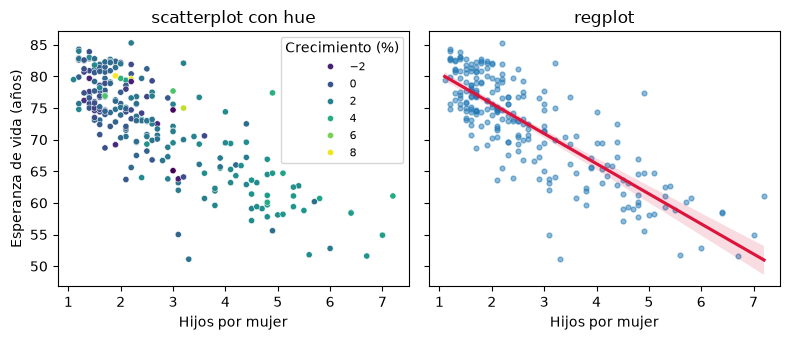

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)

sns.scatterplot(data=ancho, x="fecundidad", y="esp_vida", hue="crecimiento",
                palette="viridis", s=20, ax=axes[0])
axes[0].legend(title="Crecimiento (%)", fontsize=8)
axes[0].set_title("scatterplot con hue")

sns.regplot(data=ancho, x="fecundidad", y="esp_vida", ax=axes[1],
            scatter_kws={"s": 12, "alpha": 0.5}, line_kws={"color": "crimson"})
axes[1].set_title("regplot")

for ax in axes:
    ax.set_xlabel("Hijos por mujer")
axes[0].set_ylabel("Esperanza de vida (años)")
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()

Para ver todas las correlaciones a la vez se usa un mapa de calor. Como la matriz es simétrica, una **máscara** oculta el triángulo superior (y la diagonal, que siempre vale 1) para no mostrar cada valor dos veces. Después, ordenar los pares por su valor absoluto indica cuáles están más relacionados.

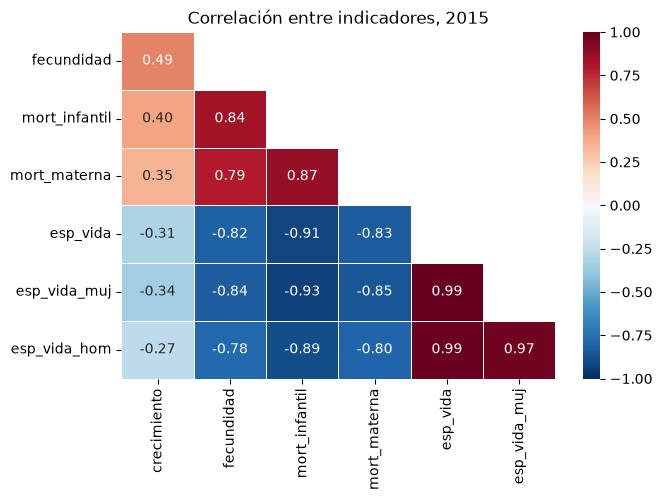

esp_vida_muj  esp_vida         0.993
esp_vida_hom  esp_vida         0.992
              esp_vida_muj     0.970
esp_vida_muj  mort_infantil   -0.930
esp_vida      mort_infantil   -0.914
esp_vida_hom  mort_infantil   -0.885
dtype: float64


In [10]:
def mapa_correlacion(corr, titulo):
    mascara = np.triu(np.ones_like(corr, dtype=bool))    # True = celda oculta
    fig, ax = plt.subplots(figsize=(7, 4.5))
    # Se quitan la primera fila y la última columna, que quedarían vacías
    sns.heatmap(corr.iloc[1:, :-1], mask=mascara[1:, :-1], annot=True, fmt=".2f",
                cmap="RdBu_r", vmin=-1, vmax=1, linewidths=0.5, ax=ax)
    ax.set_title(titulo)
    plt.show()
    return corr.where(~mascara).stack()    # pares del triángulo inferior

corr = ancho.corr()
pares = mapa_correlacion(corr, "Correlación entre indicadores, 2015")
print(pares.reindex(pares.abs().sort_values(ascending=False).index).head(6).round(3))

Los pares de esperanza de vida (total, mujeres, hombres) se correlacionan casi al 100 % porque miden casi lo mismo. Las relaciones interesantes son las que unen indicadores distintos, como la mortalidad infantil y la esperanza de vida.

## 9. Diseño para impacto visual

Un gráfico de análisis responde a quien lo hizo; un gráfico para comunicar debe responder a quien lo lee. Algunas decisiones que marcan la diferencia:

- **Un título que diga la conclusión**, no solo las variables.
- **Etiquetas en lenguaje claro y con unidades**, en lugar de los nombres de las columnas.
- **Escala de color con sentido**: para correlaciones, una paleta divergente centrada en 0 con `vmin=-1, vmax=1`.
- **Resaltar pocos puntos** con nombre, para dar ejemplos concretos.
- **Menos ruido**: sin marcos innecesarios ni elementos que no aporten.

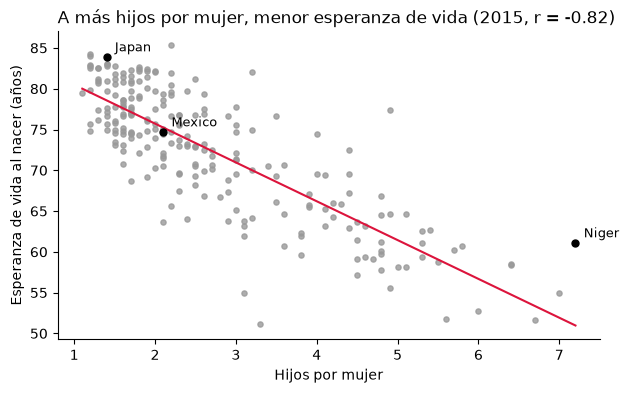

        fecundidad  esp_vida
area                        
Niger          7.2      61.1
Japan          1.4      83.9
Mexico         2.1      74.7


In [11]:
destacados = ancho.loc[["Niger", "Japan", "Mexico"]]

fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=ancho, x="fecundidad", y="esp_vida", ax=ax, ci=None,
            scatter_kws={"s": 14, "color": "0.6"}, line_kws={"color": "crimson", "lw": 1.5})
ax.scatter(destacados["fecundidad"], destacados["esp_vida"], color="black", s=25, zorder=3)
for pais, fila in destacados.iterrows():
    ax.annotate(pais, (fila["fecundidad"], fila["esp_vida"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9)

r = ancho["fecundidad"].corr(ancho["esp_vida"])
ax.set_title(f"A más hijos por mujer, menor esperanza de vida (2015, r = {r:.2f})", loc="left")
ax.set_xlabel("Hijos por mujer")
ax.set_ylabel("Esperanza de vida al nacer (años)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(destacados[["fecundidad", "esp_vida"]])

## 10. Errores frecuentes

**Usar `errors="coerce"` sin revisar lo perdido.** Como vimos en la sección 3, cifras válidas con separador de miles se convierten en `NaN` sin aviso. Conviene contar los `NaN` antes y después de convertir.

**Llamar a `pivot` con claves repetidas.** Si un mismo país tiene varios valores para la misma serie (por ejemplo, porque no se filtró el año), `pivot` no sabe cuál poner y lanza un error. Hay que filtrar antes o usar `pivot_table` con una función de agregación explícita.

In [12]:
try:
    paises.pivot(index="area", columns="serie", values="valor")    # 4 años por país
except ValueError as e:
    print("ValueError:", e)

promedio = paises.pivot_table(index="area", columns="serie", values="valor", aggfunc="mean")
print(promedio.shape)

ValueError: Index contains duplicate entries, cannot reshape
(234, 7)


**Rellenar con 0 antes de correlacionar.** Un 0 que no es un dato real se convierte en un valor extremo y cambia la correlación, como vimos en la sección 6.

**Dejar que el mapa de calor elija la escala.** Sin `vmin=-1, vmax=1`, seaborn ajusta los colores al rango de los datos: en una matriz donde todas las correlaciones son positivas, un 0.3 puede pintarse con el color más intenso. Fijar la escala y usar una paleta divergente permite leer los colores igual en cualquier matriz.

**Leer causalidad en una correlación.** Un $r$ alto justifica investigar, no concluir que una variable produce la otra.

## 11. Ejercicio

Con el mismo archivo, analiza el año **2010**:

1. Construye una tabla ancha de países (sin agregados regionales) con las siete series y nombres cortos.
2. Indica cuántos valores faltan en cada columna.
3. Calcula la matriz de correlación con pares completos y muéstrala en un mapa de calor con escala de -1 a 1.
4. Identifica el par de indicadores **distintos** más correlacionado, sin contar los pares entre las tres esperanzas de vida.
5. Grafica ese par con `regplot`, con etiquetas claras y un título que resuma la relación, y escribe una interpretación de dos frases.

### Solución

crecimiento       0
fecundidad        1
mort_infantil     1
mort_materna     49
esp_vida          1
esp_vida_muj      1
esp_vida_hom      1
dtype: int64


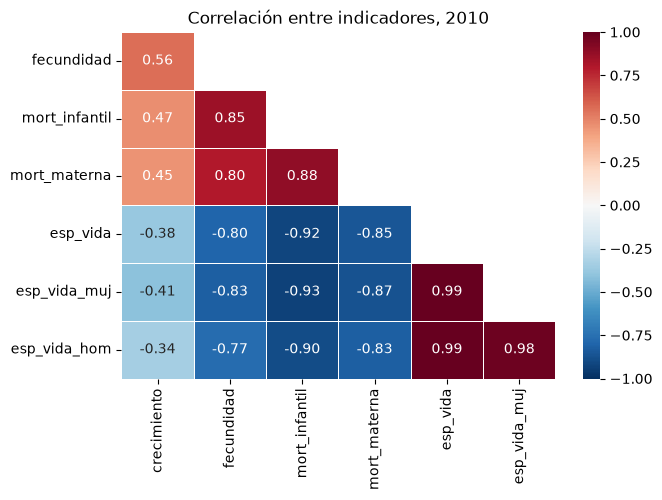

Par más correlacionado:

 ('esp_vida_muj', 'mort_infantil') -0.934


In [13]:
p2010 = paises[paises["anio"] == 2010]
tabla = (p2010.pivot(index="area", columns="serie", values="valor")
              .rename(columns=nombres_cortos)[list(nombres_cortos.values())])
tabla.columns.name = None
print(tabla.isna().sum())

pares10 = mapa_correlacion(tabla.corr(), "Correlación entre indicadores, 2010")

esperanzas = {"esp_vida", "esp_vida_muj", "esp_vida_hom"}
distintos = pares10[[not {a, b} <= esperanzas for a, b in pares10.index]]
mejor = distintos.abs().idxmax()
print("Par más correlacionado:", mejor, round(distintos[mejor], 3))

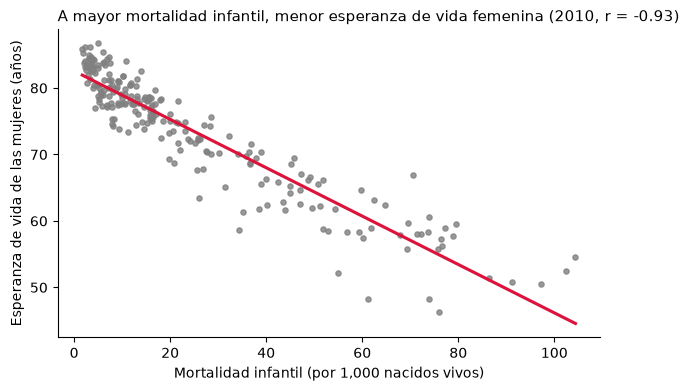

n = 233
     mort_infantil  esp_vida_muj
min            1.7          46.3
50%           15.3          76.7
max          104.4          86.7


In [14]:
etiquetas = {"mort_infantil": "Mortalidad infantil (por 1,000 nacidos vivos)",
             "esp_vida_muj": "Esperanza de vida de las mujeres (años)"}
var_y, var_x = mejor          # (fila, columna) del triángulo inferior
validos10 = tabla[[var_x, var_y]].dropna()

fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=validos10, x=var_x, y=var_y, ax=ax, ci=None,
            scatter_kws={"s": 14, "color": "0.5"}, line_kws={"color": "crimson"})
ax.set_title(f"A mayor mortalidad infantil, menor esperanza de vida femenina (2010, r = {distintos[mejor]:.2f})",
             loc="left", fontsize=11)
ax.set_xlabel(etiquetas.get(var_x, var_x))
ax.set_ylabel(etiquetas.get(var_y, var_y))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"n = {len(validos10)}")
print(validos10.describe().loc[["min", "50%", "max"]])

**Interpretación.** En 2010, la mortalidad infantil y la esperanza de vida de las mujeres tienen una correlación negativa muy fuerte (r = -0.93 en 233 países y territorios): las áreas con la mortalidad infantil más alta, por encima de 100 por cada 1,000 nacidos vivos, tienen esperanzas de vida femeninas de entre 52 y 55 años, frente a más de 85 donde la mortalidad infantil es mínima. Ambos indicadores reflejan el mismo fondo, la calidad del sistema de salud y las condiciones de vida, así que la correlación describe una asociación y no prueba que una variable cause la otra.

## Resumen

- Los datos en formato **largo** se pasan a **ancho** con `pivot` (o `pivot_table` si hay claves repetidas) para comparar variables.
- Antes de leer hay que inspeccionar el archivo crudo: `header` para encabezados de varias filas y `encoding` para la codificación.
- `to_numeric(errors="coerce")` y la limpieza en general exigen contar qué se convierte en `NaN`.
- Imputar con 0 inventa valores extremos y distorsiona la correlación; `.corr()` usa por defecto pares completos.
- Pearson mide relaciones lineales, es sensible a extremos y no demuestra causalidad.
- seaborn (`scatterplot`, `regplot`, `heatmap`) produce gráficos claros; el diseño (título con la conclusión, escala fija, resaltados) los vuelve convincentes.

En el **Módulo 11** se estudian las funciones avanzadas de Python: `lambda`, `map`, `filter` y `reduce`.